# 8. Explaining: why did the model give this woman this number?

> **In plain terms.** Glucose, BMI and age are the only inputs the model clearly relies on, and a very different kind of model (boosted trees) ranks them the same way. Risk rises steadily with glucose, rises with age until about 50 and then falls, and rises with BMI until about 30 before levelling off. For a woman the model flags, a realistic change in glucose or BMI would clear her only about three times in ten, because most flagged women are well above the cut-off.

Until now the notebooks asked how well the model predicts. This one asks why it predicts what it does. Four questions: which inputs does it rely on (E17); what shape does each effect have, and is the odd flat stretch in the BMI curve real (a question left over from Milestone 4); do the explanation tools agree with the model's exact arithmetic, and with a very different kind of model; and for one woman the model flags, what small change would move her below the cut-off (E18)? Because the published model is a sum of one effect per input, every explanation here can be checked against an exact answer. That is unusual and is part of the point.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 8.1 Which inputs does the model rely on?

**What we're looking for.** How much worse the model gets on women it has never seen when one input is scrambled.

In [2]:
import json
import numpy as np
from src.data import load_data, FEATURES
from src.modeling import current_features
from src import explain, figures

X, y = load_data()
Xc = X[current_features(FEATURES)]
m6 = json.load(open("../reports/metrics.json"))["m6"]
table = pd.DataFrame(m6["permutation"]).T
table.columns = ["AUC lost (mean)", "low (2.5%)", "high (97.5%)", "share of splits with a loss"]
table.sort_values("AUC lost (mean)", ascending=False)

,AUC lost (mean),low (2.5%),high (97.5%),share of splits with a loss
Glucose,0.168,0.118,0.215,1.000
BMI,0.070,0.034,0.099,1.000
Age,0.042,0.018,0.066,1.000
DiabetesPedigreeFunction,0.010,-0.002,0.020,0.960
Pregnancies,0.003,-0.007,0.008,0.800
BloodPressure,0.001,-0.006,0.005,0.580


**How to read it.** This is permutation importance. For each of the 50 train/test splits the model is fitted on the training women. Then one input of the test women is shuffled among them, five times, which breaks its link with the outcome, and the fall in AUC is recorded. A bigger fall means the model leaned harder on that input. `low` and `high` are the 2.5th and 97.5th percentiles of the fall over the 50 splits, so they describe how much it varies from split to split.

**What it means.** Glucose dominates: scrambling it costs 0.17 of AUC, more than BMI (0.07) and age (0.04) together. The other three inputs cost 0.01 or less, and for each of them the range includes zero or sits right at it, so the model gains nothing measurable from pregnancies, blood pressure or family history on women it has not seen. That is no reason to drop them yet: they cost nothing to keep, they add a little to the odds the page displays, and the AUC is a blunt measure.

**What's next and why.** Importance says how much an input matters, not how. Next, the shape of each effect.

## 8.2 What shape does each effect have?

**What we're looking for.** How a woman's predicted risk moves as one input changes while everything else stays as it is.

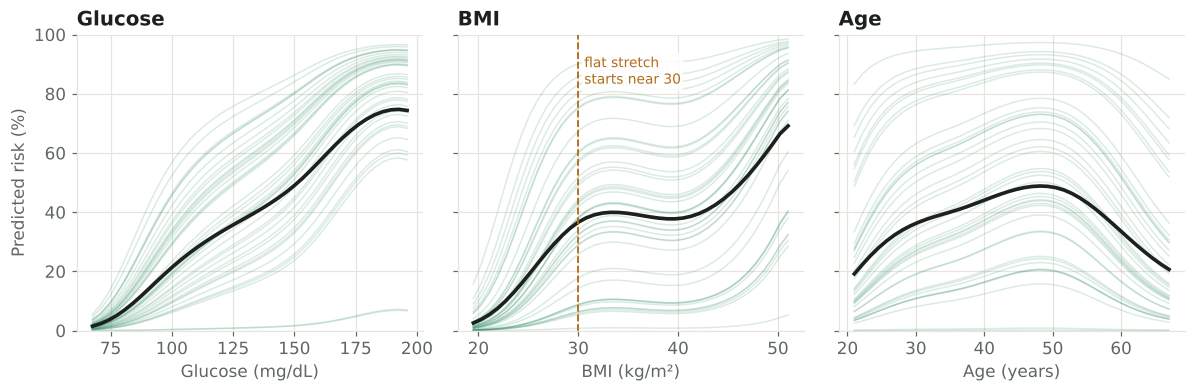

In [3]:
figures.m6_curves();

**How to read it.** Each faint green line is one of 40 real women (a curve known as an ICE line, for individual conditional expectation): her predicted risk if only that one measurement were changed. The bold black line is the average of those lines over all 768 women (a partial dependence curve). The lines run parallel because the model is a sum of one effect per input: changing glucose moves everyone the same way on the odds scale, and the probability scale squeezes the high-risk lines against 100%.

**What it means.** Glucose rises steadily. Age rises to about 50 and then falls, matching the real rates found in Milestone 3 (71% at 50 to 54, 28% at 60 and over). BMI rises sharply to about 30, then runs flat until about 40 and climbs again. The parallel lines are an assumption of the model, not a finding: a model with interactions could show lines that cross. Milestone 3 tested age by glucose and found nothing, which is why the model has none.

**What's next and why.** The flat stretch in BMI was noted in Milestone 4 as possibly noise. Test it directly.

## 8.3 Is the flat stretch in BMI real?

**What we're looking for.** Whether the BMI curve really levels off between about 30 and 42, or only looks that way because few women sit there.

In [4]:
bp = m6["bmi_plateau"]
pd.DataFrame({
    "log-odds rise": {"BMI 24 to 30": bp["estimate"]["low_to_start"], "BMI 30 to 42": bp["estimate"]["plateau"]},
    "95% range, low": {"BMI 24 to 30": bp["interval"]["low_to_start"][0], "BMI 30 to 42": bp["interval"]["plateau"][0]},
    "95% range, high": {"BMI 24 to 30": bp["interval"]["low_to_start"][1], "BMI 30 to 42": bp["interval"]["plateau"][1]},
    "odds multiplier": {"BMI 24 to 30": bp["odds"]["24_to_30"], "BMI 30 to 42": bp["odds"]["30_to_42"]},
})

,log-odds rise,"95% range, low","95% range, high",odds multiplier
BMI 24 to 30,1.678,1.138,2.389,5.357
BMI 30 to 42,0.171,-0.375,0.852,1.187


**How to read it.** The model was refitted on 300 resamples of the 768 women (the bootstrap), and the BMI curve read at 24, 30 and 42 with every other input at its median. The table shows the rise in log-odds from 24 to 30 and from 30 to 42, with the 2.5th and 97.5th percentiles over the 300 refits. Log-odds are the scale the model adds on; `odds multiplier` is e raised to that rise.

**What it means.** From BMI 24 to 30 the odds multiply by about 5.4, and the whole range (3.1 to 10.9) is well above 1. From 30 to 42 the best estimate is only a 1.2 times rise, with a range from 0.7 to 2.3 times. If the early slope had simply continued, the rise over those 12 points would be about 29 times (3.4 in log-odds), far outside the range. So the levelling-off is real. What the data cannot say is whether it is exactly flat: a rise of up to 2.3 times is still possible, and so is a slight fall. Compare with the second test, below.

**What's next and why.** The second test asks whether the curve matters for prediction.

## 8.4 Does a straight line for BMI do as well?

**What we're looking for.** Whether bending BMI improves predictions on women the model hasn't seen.

In [5]:
cv = bp["curve_vs_straight_bmi"]
pd.Series({"AUC, curve for BMI (published)": cv["auc_curve"], "AUC, straight line for BMI": cv["auc_straight"],
           "difference": cv["diff"], "95% range, low": cv["low"], "95% range, high": cv["high"],
           "p-value (corrected t-test)": cv["p"], "share of splits the curve wins": cv["wins"]}).to_frame("value")

,value
"AUC, curve for BMI (published)",0.853
"AUC, straight line for BMI",0.847
difference,0.006
"95% range, low",-0.002
"95% range, high",0.015
p-value (corrected t-test),0.149
share of splits the curve wins,0.800


**How to read it.** Two models scored on the same 50 splits: the published one, and one that is identical except that BMI is a straight line (curves remain for glucose and age). The difference is tested with the corrected resampled t-test used in Milestone 4, which allows for the splits sharing women.

**What it means.** The curve scores 0.006 higher and wins on 80% of splits, but the range runs from slightly below zero to 0.015 and the p-value is 0.15, so this could be chance. The curve is kept, because it matches what the bootstrap showed and costs nothing. But the claim is modest: the BMI curve's *shape* is real, and its *benefit* for prediction is likely, not proven. This is the same rating that curves-versus-straight-lines received in Milestone 4.

**What's next and why.** Now check the explanation tools themselves, starting with SHAP.

## 8.5 Does SHAP agree with the model's exact answer?

**What we're looking for.** Whether a standard explanation tool reproduces the contributions we can compute exactly for this model.

In [6]:
sh = m6["shap"]
pd.DataFrame({"mean |SHAP| (log-odds)": sh["mean_abs_shap"], "share": sh["share"]}).sort_values("share", ascending=False).assign(
    **{"largest gap from exact": sh["max_abs_difference"]}).iloc[:1].T.rename(columns=lambda c: "glucose" if c == "Glucose" else c)

,glucose
mean |SHAP| (log-odds),0.930
share,0.364
largest gap from exact,0.002


**How to read it.** SHAP gives each input a share of the credit for a woman's prediction, by averaging its effect over every order in which inputs could be added. The model here is a sum of one effect per input, so the exact answer is simple: each input's contribution minus the average contribution over a background group of 100 women. The exact SHAP algorithm was run for all 768 women and compared with that formula. The table shows glucose's average size and the single largest gap found anywhere, for any woman or input.

**What it means.** Glucose carries 36% of the total importance. The largest gap between SHAP and the exact answer anywhere is 0.002 in log-odds, and the average gap is under a millionth, so SHAP is working as it should. On a model this simple SHAP tells us nothing new. The point is that it is now verified, so it can be trusted on a model where no exact answer exists. The next section does that.

**What's next and why.** Use SHAP on a boosted-tree model and see whether it tells the same story.

## 8.6 Does a very different model tell the same story?

**What we're looking for.** Whether the ranking of inputs belongs to the data or to the kind of model.

In [7]:
b = m6["boosted"]
pd.DataFrame({"published model": b["published_share"], "boosted trees (XGBoost)": b["boosted_share"]}).mul(100).sort_values(
    "published model", ascending=False)

,published model,boosted trees (XGBoost)
Glucose,36.391,34.812
BMI,25.987,23.789
Age,20.661,18.568
DiabetesPedigreeFunction,7.999,10.698
Pregnancies,5.313,6.580
BloodPressure,3.649,5.554


**How to read it.** Each column is the share of total mean |SHAP| going to that input, in per cent. The boosted-tree model is XGBoost with 200 small trees, fitted on all 768 women. It has no formula to read, so SHAP is the only way to see what it uses. The two columns should be compared by order and rough size.

**What it means.** The order is identical (rank correlation 1.0): glucose, BMI, age, family history, pregnancies, blood pressure. The sizes are close too, with the boosted model giving slightly more weight to family history, pregnancies and blood pressure. So the ranking is about the data. A model that finds its own shapes, without being told where to put curves, ends up where the curved logistic model did.

**What's next and why.** Put all this together for one woman, and then ask what would change her result.

## 8.7 One woman, explained

**What we're looking for.** Each input's push on one woman's risk, and the number that results.

In [8]:
import numpy as np
from src import nonlinear as nl
m = nl.export_curves_model(Xc, y)
woman = {"Pregnancies": 2, "Glucose": 122, "BloodPressure": 72.0, "BMI": 31.0, "DiabetesPedigreeFunction": 0.45, "Age": 30}
vals = [woman[f] for f in m["features"]]
risk = 1 / (1 + np.exp(-explain._z(m, vals)))
table = pd.DataFrame({"her value": vals, "typical woman": m["median"],
                      "odds multiplier": [np.exp(np.interp(v, m["grid"][f], m["contribution"][f])) for f, v in zip(m["features"], vals)]},
                     index=m["features"])
print(f"Predicted risk: {risk:.0%}")
table

Predicted risk: 40%


,her value,typical woman,odds multiplier
Pregnancies,2.000,3.000,0.952
Glucose,122.000,117.000,1.149
BloodPressure,72.000,72.000,1.000
BMI,31.000,32.300,0.926
DiabetesPedigreeFunction,0.450,0.372,1.067
Age,30.000,29.000,1.069


**How to read it.** `odds multiplier` is the same number the project page shows beside each bar: how much that input multiplies the odds compared with a typical woman (one with the median of every measurement). Multipliers above 1 push the risk up and below 1 push it down. Multiplying all six and applying them to a typical woman's odds gives the risk.

**What it means.** This woman's risk is 40%. Her glucose of 122 (a little above typical) multiplies the odds by 1.15, her BMI of 31 lowers them slightly (0.93, because the typical BMI here is 32), and everything else is within a few per cent of typical. She sits a little above the cut-off at 0.33 and well above at 0.17. Notice that no single input explains her number: a woman near the middle on everything lands near the population rate, which is 35%.

**What's next and why.** Ask the question the page now answers: how far is she from the cut-off?

## 8.8 What would change this? (E18)

**What we're looking for.** The smallest drop in glucose, or in BMI, that would move her below each cut-off.

In [9]:
rows = []
for ratio, cut in [(2, 0.33), (5, 0.17), (10, 0.09)]:
    g = explain.counterfactual(m, vals, cut, "Glucose", explain.LIMITS["Glucose"])
    b = explain.counterfactual(m, vals, cut, "BMI", explain.LIMITS["BMI_share"] * woman["BMI"])
    rows.append({"a missed case is": f"{ratio}x a false alarm", "cut-off": cut,
                 "glucose drop needed (mg/dL)": g["needed"], "BMI drop needed": b["needed"]})
pd.DataFrame(rows).set_index("a missed case is")

,cut-off,glucose drop needed (mg/dL),BMI drop needed
a missed case is,,,
2x a false alarm,0.330,10.000,2.100
5x a false alarm,0.170,NaN,NaN
10x a false alarm,0.090,NaN,NaN


**How to read it.** For each cut-off the code lowers one input at a time, in steps of 1 mg/dL for glucose and 0.1 for BMI, until her risk falls below the cut-off, and reports the first step that works. It stops at a modest limit: 20 mg/dL for glucose, 10% of her BMI for BMI. A blank (None) means no change within the limit is enough. The page runs the same search in your browser, and a test checks that the two agree.

**What it means.** At the 2 times cut-off (0.33) her glucose would need to be 10 lower (112), or her BMI 2.1 lower (28.9). At 0.17 and 0.09, nothing within the limits is enough, because she is too far above those lower cut-offs. This is a statement about the model: it says what moves the number. It does not say that lowering her glucose would lower her real risk. The model describes patterns across 768 women, not cause and effect.

**What's next and why.** Run the same search over every woman the model flags.

## 8.9 How many flagged women are one small change away?

**What we're looking for.** The share of flagged women whom a realistic change would clear, at each of the three cut-offs.

,2x (0.33),5x (0.17),10x (0.09)
women flagged,344.000,477.000,564.000
median risk of flagged women,0.612,0.495,0.428
cleared by glucose alone,0.334,0.279,0.227
cleared by BMI alone,0.140,0.128,0.108
cleared by either,0.355,0.289,0.241


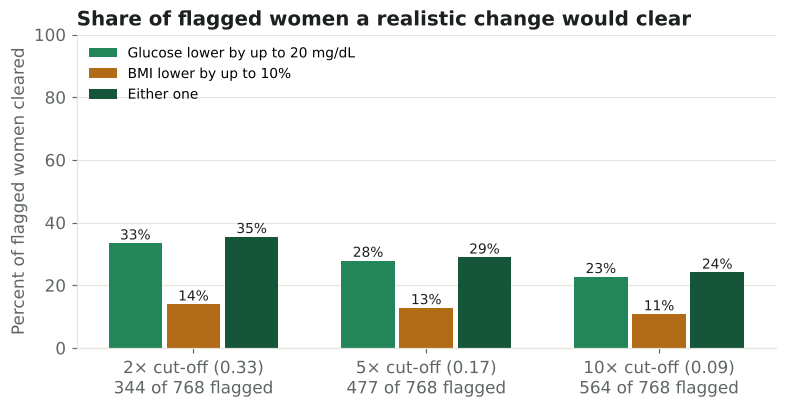

In [10]:
figures.m6_counterfactual();
cf = m6["counterfactual"]
pd.DataFrame({f"{r}x ({v['cutoff']:.2f})": {"women flagged": v["flagged"], "median risk of flagged women": v["flagged_risk_median"],
              "cleared by glucose alone": v["glucose_alone"], "cleared by BMI alone": v["bmi_alone"], "cleared by either": v["either"]}
              for r, v in cf.items()})

**How to read it.** The search from 8.8 is run for every flagged woman, using the full-data model for both her flag and her change. Each bar is the share of flagged women cleared by lowering glucose by up to 20 mg/dL, lowering BMI by up to 10%, or either. The table adds how many women are flagged and the median risk among them.

**What it means.** At the page's 5 times cut-off (0.17), 477 of 768 women are flagged and their median risk is 49%, almost three times the cut-off. A realistic change clears only 29% of them (glucose alone 28%, BMI alone 13%; the typical change needed is 12 mg/dL of glucose or 1.4 BMI points). Among flagged women whose risk is under 30%, 94% can be cleared, so the search does work near the cut-off. The share cleared falls as the cut-off falls, from 35% at 0.33 to 24% at 0.09, because a lower cut-off flags more women and moves the threshold further away from each of them. The honest summary is that most flagged women are not a small change away.

**What's next and why.** Decide what goes on the page and in the findings.

## 8.10 What this changes

**What we're looking for.** Whether anything here alters the published model, the cut-off, or the claims.

In [11]:
pd.Series({"Published model changed": "no",
           "Cut-off changed": "no (0.17 at 5 times)",
           "New on the page": "importance chart, curve shapes, 'What would change this?' box",
           "BMI curve": "shape real; benefit likely, not proven (p = 0.15)",
           "SHAP": "verified against the exact answer (largest gap 0.002 log-odds)"}).to_frame("decision")

,decision
Published model changed,no
Cut-off changed,no (0.17 at 5 times)
New on the page,"importance chart, curve shapes, 'What would ch..."
BMI curve,"shape real; benefit likely, not proven (p = 0.15)"
SHAP,verified against the exact answer (largest gap...


**How to read it.** A summary of the decisions this notebook supports, in one table.

**What it means.** Nothing about the model changes. Milestone 6 adds explanation, not performance. The two claims it sharpens are that glucose is the only input the model clearly needs, and that the BMI curve's shape is real while its benefit for prediction is only likely. D20 records that the page explains the model by its exact contributions and not by SHAP, because the exact version is simpler and SHAP agrees with it.

**What's next and why.** Milestone 7 asks how sure the model is about one woman's estimate, which this notebook did not touch: every risk here is a single number with no range around it.